# Modelo de valor: del recall@12 a quetzales al mes
`ventas_v = visitas x f_ve x CTR_v x conv_click x ticket`, `CTR_v = ctr_ref x recall_v/recall_A`. Fuentes en `docs/supuestos_valor.md`.

In [1]:
import os, sys
os.chdir(os.path.abspath('..')); sys.path.insert(0, 'src')
import pandas as pd
from IPython.display import Image
from evaluation import modelo_valor as mv
main_out = mv.main()

         version  recall@12_test  ventas_mes_Q  extra_ventas_vs_A_Q  costo_servidor_Q  extra_neto_Q
               A        0.074333 103541.760000             0.000000             0.000      0.000000
Regla sin modelo        0.103451 144101.524407         40559.764407             0.000  40559.764407
               B        0.105188 146521.069389         42979.309389           167.097  42812.212389
               C        0.103608 144320.216729         40778.456729           334.194  40444.262729
 k        A  Regla sin modelo
 4 0.032394          0.053679
 8 0.054915          0.082788
12 0.074333          0.103451
24 0.122944          0.149807
B genera Q42,979 más al mes que A, con un costo extra de Q167 (extra neto Q42,812)
C genera Q40,778 más al mes que A, con un costo extra de Q334 (extra neto Q40,444)
Regla sin modelo genera Q40,560 más al mes que A, con un costo extra de Q0 (extra neto Q40,560)
ok


## Supuestos

In [2]:
pd.DataFrame(mv.SUPUESTOS, index=['valor','bajo','alto','descripción','fuente']).T

,valor,bajo,alto,descripción,fuente
visitas,321000,226000,600000,visitas/mes al sitio,"Semrush (321K sep-2026; 226K feb-2026, solo tr..."
f_ve,0.5,0.25,0.75,fracción de visitas que ven el carrusel,supuesto del equipo
ctr_ref,0.02,0.01,0.04,CTR del carrusel con la lista de A,supuesto del equipo (blogs/tests: 1.4 %-6.5 %)
conv_click,0.036,0.008,0.036,compra tras clic en el carrusel,Salesforce: 0.8 % LatAm x 4.5 (clic en recomen...
ticket,896.0,400.0,1100.0,Q por compra,datos del proyecto (transacciones.csv); Cámara...
tc,7.63,7.5,7.8,Q por USD,"Banguat vía prensa, abr-2026"
precio_hora_usd,0.03,0.03,0.06,USD/h CPU Upgrade,Hugging Face Spaces (doc oficial)


## Valor por versión

In [3]:
val, sens, rk = main_out
val

,version,recall@12_test,ventas_mes_Q,extra_ventas_vs_A_Q,costo_servidor_Q,extra_neto_Q
0,A,0.074333,103541.760000,0.000000,0.000,0.000000
1,Regla sin modelo,0.103451,144101.524407,40559.764407,0.000,40559.764407
2,B,0.105188,146521.069389,42979.309389,167.097,42812.212389
3,C,0.103608,144320.216729,40778.456729,334.194,40444.262729


In [4]:
rk

,k,A,Regla sin modelo
0,4,0.032394,0.053679
1,8,0.054915,0.082788
2,12,0.074333,0.103451
3,24,0.122944,0.149807


In [5]:
sens[sens.cambio.isin(['base','pesimista','optimista'])]

,supuesto,cambio,valor,extra_neto_B_Q,delta_vs_base_Q,delta_vs_base_pct
0,base,base,NaN,42812.212389,0.000000,0.000000
29,todos,pesimista,NaN,421.985518,-42390.226871,-99.014334
30,todos,optimista,NaN,295706.435055,252894.222666,590.705802


## Figuras

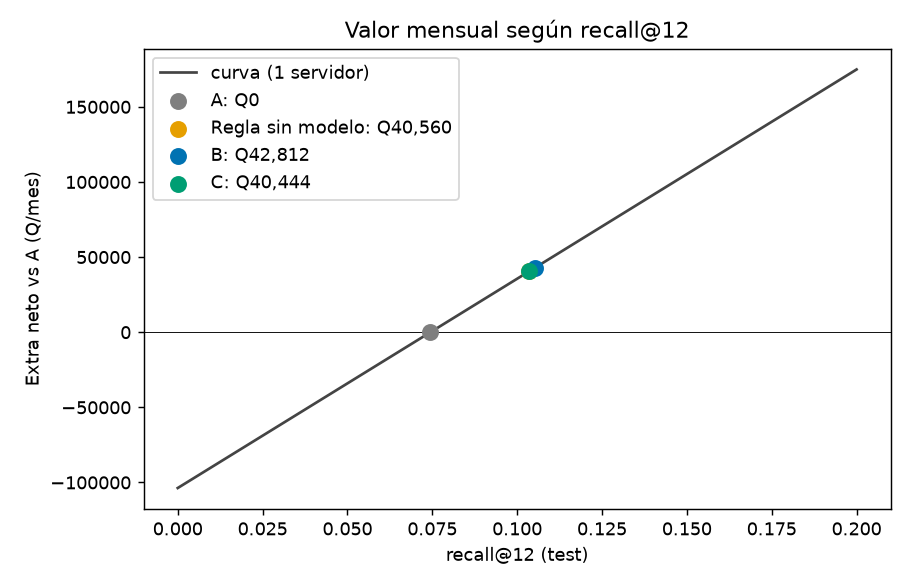

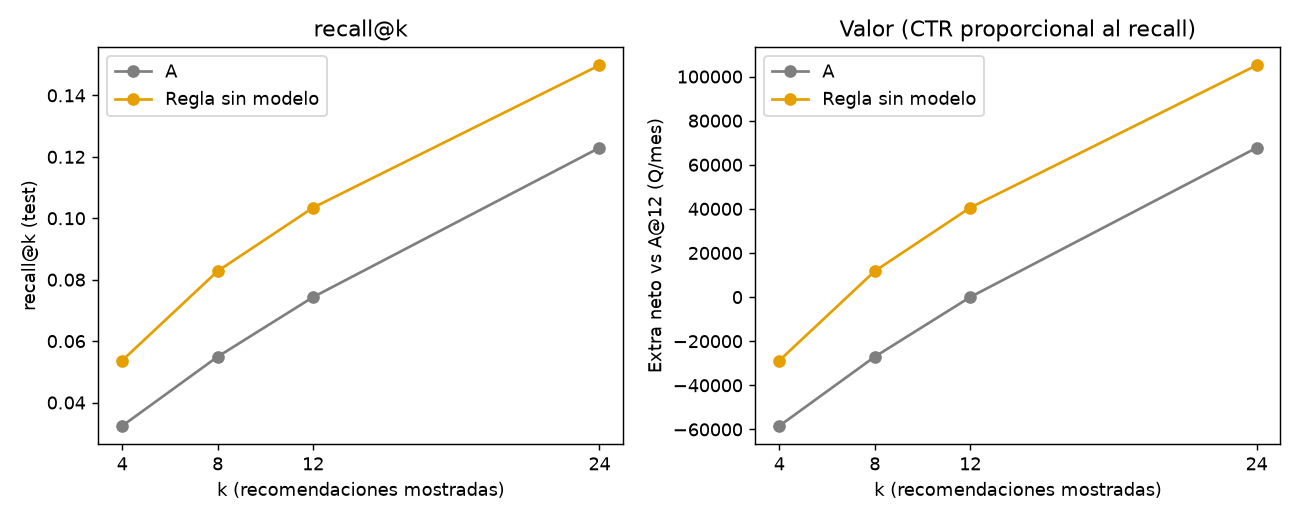

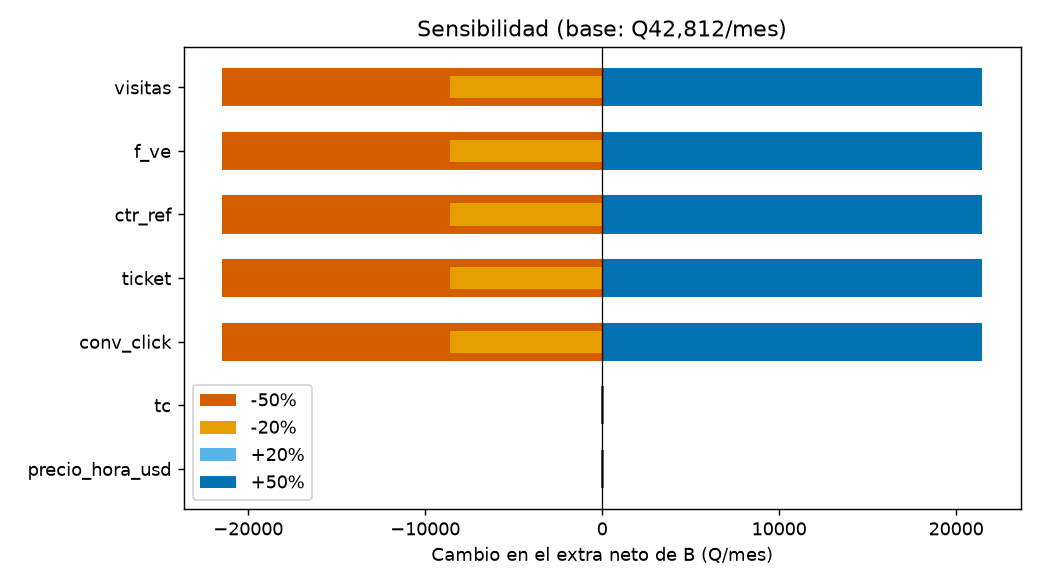

In [6]:
for f in ['valor_curva_recall','valor_curva_k','valor_sensibilidad']:
    display(Image(f'reports/figuras/{f}.png'))

## Interpretación
- B supera a A en unos Q43 mil al mes; el costo de servidor (Q167 a Q334) es despreciable frente al aumento de ventas.
- La regla sin modelo (popularidad + recompra) captura casi todo ese valor: B solo agrega ~Q2 mil, y C queda por debajo de la regla. Con estos datos el deep learning no justifica por sí solo el costo extra.
- La sensibilidad la dominan los supuestos multiplicativos de demanda (visitas, `f_ve`, `ctr_ref`, `conv_click`, ticket); todos mueven el extra de forma proporcional, y el costo de servidor casi no importa.
- Para k, solo se calculó A y la regla (B/C requieren modificar `two_tower.py`). Se supone CTR proporcional al recall, sin dilución de atención al mostrar más prendas.